<h1><center>BERT</h1></center>

Bidirectional Encoders Representations from Transformers. Это Encoder-only архитектураЖ классификация текстов, различный анализ. Т.е задача извлечения признаков их текста.
Т.е модель не может генерировать ответ, только извлекает (находит) из текста.
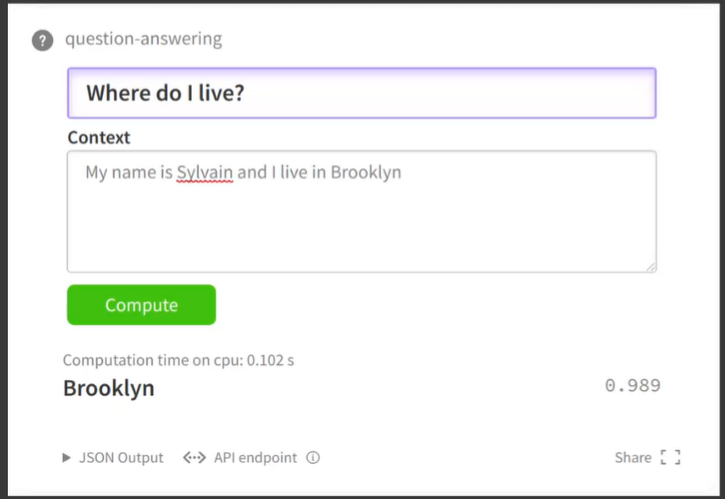

!pip install datasets transformers
!pip install accelerate -U

In [10]:
squad_v2 = False
model_checkpoint = 'D:/MIREA/DPO/Learning/Practic2_20/prajjwa1/bert-tiny'
batch_size = 16

<h2>Загрузка датасета

In [4]:
from datasets import load_dataset


datasets = load_dataset('rajpurkar/squad_v2' if squad_v2 else 'rajpurkar/squad')

In [5]:
datasets

DatasetDict({
    train: Dataset({
        features: ['id', 'title', 'context', 'question', 'answers'],
        num_rows: 87599
    })
    validation: Dataset({
        features: ['id', 'title', 'context', 'question', 'answers'],
        num_rows: 10570
    })
})

In [6]:
datasets['train'][0]

{'id': '5733be284776f41900661182',
 'title': 'University_of_Notre_Dame',
 'context': 'Architecturally, the school has a Catholic character. Atop the Main Building\'s gold dome is a golden statue of the Virgin Mary. Immediately in front of the Main Building and facing it, is a copper statue of Christ with arms upraised with the legend "Venite Ad Me Omnes". Next to the Main Building is the Basilica of the Sacred Heart. Immediately behind the basilica is the Grotto, a Marian place of prayer and reflection. It is a replica of the grotto at Lourdes, France where the Virgin Mary reputedly appeared to Saint Bernadette Soubirous in 1858. At the end of the main drive (and in a direct line that connects through 3 statues and the Gold Dome), is a simple, modern stone statue of Mary.',
 'question': 'To whom did the Virgin Mary allegedly appear in 1858 in Lourdes France?',
 'answers': {'text': ['Saint Bernadette Soubirous'], 'answer_start': [515]}}

<h2>Предобработка данных

In [53]:
from transformers import AutoTokenizer


tokenizer = AutoTokenizer.from_pretrained(model_checkpoint, use_local_files=True, use_fast=True)

tokenizer.pad_token = '[PAD]'
tokenizer.cls_token = '[CLS]'
tokenizer.sep_token = '[SEP]'

In [54]:
tokenizer(
    'Hey you know what I did last night?',
    'You\'d better not bring my mother into this!',
    return_token_type_ids=True
)

{'input_ids': [101, 4931, 2017, 2113, 2054, 1045, 2106, 2197, 2305, 1029, 102, 2017, 1005, 1040, 2488, 2025, 3288, 2026, 2388, 2046, 2023, 999, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}

In [ ]:
max_length = 384
doc_stride = 128

pad_on_right = tokenizer.padding_side == 'right'

In [62]:
def prepare_train_features(examples):
    examples['question'] = [q.lstrip() for q in examples['question']]
    tokenized_examples = tokenizer(
        examples['question' if pad_on_right else 'context'],
        examples['context' if pad_on_right else 'question'],
        truncation='only_second' if pad_on_right else 'only_first',
        max_length=max_length,
        stride=doc_stride,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        return_token_type_ids=True,
        padding='max_length',
    )
    sample_mapping = tokenized_examples.pop('overflow_to_sample_mapping')
    offset_mapping = tokenized_examples.pop('offset_mapping')

    tokenized_examples['start_positions'] = []
    tokenized_examples['end_positions'] = []

    for i, offsets in enumerate(offset_mapping):
        input_ids = tokenized_examples['input_ids'][i]
        cls_index = input_ids.index(tokenizer.cls_token_id)

        sequence_ids = tokenized_examples.sequence_ids(i)

        sample_index = sample_mapping[i]
        answers = examples['answers'][sample_index]

        if len(answers['answer_start']) == 0:   
            tokenized_examples['start_positions'].append(cls_index)
            tokenized_examples['end_positions'].append(cls_index)
        else:
            start_char = answers['answer_start'][0]
            end_char = start_char + len(answers['text'][0])

            token_start_index = 0
            while sequence_ids[token_start_index] != (1 if pad_on_right else 0):
                token_start_index += 1

            token_end_index = len(input_ids) - 1
            while sequence_ids[token_end_index] != (1 if pad_on_right else 0):
                token_end_index -= 1
            
            if not(offsets[token_start_index][0] <= start_char and 
                   offsets[token_end_index][1] >= end_char):
                tokenized_examples['start_positions'].append(cls_index)
                tokenized_examples['end_positions'].append(cls_index)
            else:
                while token_start_index < len(offsets) and offsets[token_start_index][0] <= start_char:
                    token_start_index += 1
                tokenized_examples['start_positions'].append(token_start_index - 1)
                
                while offsets[token_end_index][1] >= end_char:
                    token_end_index -= 1
                tokenized_examples['end_positions'].append(token_end_index - 1)
    return tokenized_examples

In [65]:
features = prepare_train_features(datasets['train'][:5])
print(features)

{'input_ids': [[101, 2000, 3183, 2106, 1996, 6261, 2984, 9382, 3711, 1999, 8517, 1999, 10223, 26371, 2605, 1029, 102, 6549, 2135, 1010, 1996, 2082, 2038, 1037, 3234, 2839, 1012, 10234, 1996, 2364, 2311, 1005, 1055, 2751, 8514, 2003, 1037, 3585, 6231, 1997, 1996, 6261, 2984, 1012, 3202, 1999, 2392, 1997, 1996, 2364, 2311, 1998, 5307, 2009, 1010, 2003, 1037, 6967, 6231, 1997, 4828, 2007, 2608, 2039, 14995, 6924, 2007, 1996, 5722, 1000, 2310, 3490, 2618, 4748, 2033, 18168, 5267, 1000, 1012, 2279, 2000, 1996, 2364, 2311, 2003, 1996, 13546, 1997, 1996, 6730, 2540, 1012, 3202, 2369, 1996, 13546, 2003, 1996, 24665, 23052, 1010, 1037, 14042, 2173, 1997, 7083, 1998, 9185, 1012, 2009, 2003, 1037, 15059, 1997, 1996, 24665, 23052, 2012, 10223, 26371, 1010, 2605, 2073, 1996, 6261, 2984, 22353, 2135, 2596, 2000, 3002, 16595, 9648, 4674, 2061, 12083, 9711, 2271, 1999, 8517, 1012, 2012, 1996, 2203, 1997, 1996, 2364, 3298, 1006, 1998, 1999, 1037, 3622, 2240, 2008, 8539, 2083, 1017, 11342, 1998, 1996, 2

In [77]:
tokenized_datasets = datasets.map(prepare_train_features, batched=True,
                              remove_columns=datasets['train'].column_names)

<h2>Дообучение модели

In [74]:
from transformers import AutoModelForQuestionAnswering, TrainingArguments, Trainer


model = AutoModelForQuestionAnswering.from_pretrained(model_checkpoint, local_files_only=True)

Loading weights:   0%|          | 0/37 [00:00<?, ?it/s]

[transformers] BertForQuestionAnswering LOAD REPORT from: D:/MIREA/DPO/Learning/Practic2_20/prajjwa1/bert-tiny
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
qa_outputs.bias                            | MISSING    | 
qa_outputs.weight                          | MISSING    | 

Not

In [75]:
model_name = model_checkpoint.split('/')[-1]
args = TrainingArguments(
    f'{model_name}-finutuned-squad',
    eval_strategy='epoch',
    learning_rate=2e-5,
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    num_train_epochs=5,
    weight_decay=.01
)

In [79]:
from transformers import default_data_collator


data_collator = default_data_collator

trainer = Trainer(
    model,
    args,
    train_dataset=tokenized_datasets['train'],
    eval_dataset=tokenized_datasets['validation'],
    data_collator=data_collator,
    processing_class=tokenizer
)

In [80]:
model

BertForQuestionAnswering(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 128, padding_idx=0)
      (position_embeddings): Embedding(512, 128)
      (token_type_embeddings): Embedding(2, 128)
      (LayerNorm): LayerNorm((128,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-1): 2 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=128, out_features=128, bias=True)
              (key): Linear(in_features=128, out_features=128, bias=True)
              (value): Linear(in_features=128, out_features=128, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=128, out_features=128, bias=True)
              (LayerNorm): LayerNorm((128,), eps=1e

In [82]:
trainer.train()

Epoch,Training Loss,Validation Loss
1,3.595875,3.352959
2,3.402781,3.191578
3,3.300896,3.100332
4,3.226598,3.069093
5,3.212909,3.046544


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=27665, training_loss=3.4066909599752337, metrics={'train_runtime': 878.1591, 'train_samples_per_second': 504.032, 'train_steps_per_second': 31.503, 'total_flos': 407816505686016.0, 'train_loss': 3.4066909599752337, 'epoch': 5.0})

In [83]:
trainer.save_model('test-squad-trained')

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

<h2>Валидация модели

In [88]:
import torch


for batch in trainer.get_eval_dataloader():
    break
batch = {k: v.to(trainer.args.device) for k, v in batch.items()}
with torch.inference_mode():
    output = trainer.model(**batch)
output.keys()

odict_keys(['loss', 'start_logits', 'end_logits'])

In [90]:
import numpy as np


n_best_size = 20
start_logits = output.start_logits[0].cpu().numpy()
end_logits = output.end_logits[0].cpu().numpy()
start_indexes = np.argsort(start_logits)[-1: -n_best_size - 1: -1].tolist()
end_indexes = np.argsort(end_logits)[-1: -n_best_size - 1: -1].tolist()
valid_answers = []
for start_index in start_indexes:
    for end_index in end_indexes:
        if start_index <= end_index:
            valid_answers.append(
                {
                'score': start_logits[start_index] + end_logits[end_index],
                'text': ''
                }
            )



In [95]:
def prepare_validation_features(examples):
    examples['question'] = [q.lstrip() for q in examples['question']]
    tokenized_examples = tokenizer(
        examples['question' if pad_on_right else 'context'],
        examples['context' if pad_on_right else 'question'],
        truncation='only_second' if pad_on_right else 'only_first',
        max_length=max_length,
        stride=doc_stride,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        return_token_type_ids=True,
        padding='max_length',
    )
    sample_mapping = tokenized_examples.pop('overflow_to_sample_mapping')
    tokenized_examples['example_id'] = []

    for i in range(len(tokenized_examples['input_ids'])):
        sequence_ids = tokenized_examples.sequence_ids(i)
        context_index = 1 if pad_on_right else 0
        sample_index = sample_mapping[i]
        tokenized_examples['example_id'].append(examples['id'][sample_index])
        tokenized_examples['offset_mapping'][i] = [
            (o if sequence_ids[k] == context_index else None)
            for k, o in enumerate(tokenized_examples['offset_mapping'][i])

        ]
    return tokenized_examples

In [96]:
validation_features = datasets['validation'].map(
    prepare_validation_features,
    batched=True,
    remove_columns=datasets['validation'].column_names
)

Map:   0%|          | 0/10570 [00:00<?, ? examples/s]

In [99]:
raw_predicitons = trainer.predict(validation_features)
raw_predicitons

PredictionOutput(predictions=(array([[ 0.22545846, -6.729576  , -6.3684587 , ..., -6.6712265 ,
        -6.6925807 , -6.678607  ],
       [ 0.39407936, -6.7409654 , -6.3799305 , ..., -6.6750083 ,
        -6.693266  , -6.6791024 ],
       [ 0.09034663, -6.713617  , -6.820811  , ..., -6.8385725 ,
        -6.773919  , -6.7698936 ],
       ...,
       [-0.03488486, -6.5495462 , -6.8106637 , ..., -6.7396393 ,
        -6.6943107 , -6.699734  ],
       [ 0.5553974 , -6.605781  , -6.6015267 , ..., -6.7347226 ,
        -6.728448  , -6.735354  ],
       [ 0.27860522, -6.5734334 , -6.838967  , ..., -6.787967  ,
        -6.7292204 , -6.7402964 ]], shape=(10784, 384), dtype=float32), array([[-0.61906457, -6.528597  , -6.746482  , ..., -6.5832767 ,
        -6.583239  , -6.537977  ],
       [-0.46074116, -6.527334  , -6.745943  , ..., -6.5820866 ,
        -6.5871096 , -6.5402837 ],
       [-0.7607814 , -6.637772  , -6.4917593 , ..., -6.558361  ,
        -6.5904837 , -6.5529    ],
       ...,
       [-

In [100]:
raw_predicitons.predictions[1].shape

(10784, 384)

In [101]:
validation_features.set_format(type=validation_features.format['type'],
                               columns=list(validation_features.features.keys()))
max_answer_length = 30

start_logits = output.start_logits[5].cpu().numpy()
end_logits = output.end_logits[5].cpu().numpy()
offset_mapping = validation_features[5]['offset_mapping']
context = datasets['validation'][5]['context']
start_indexes = np.argsort(start_logits)[-1: -n_best_size - 1: -1].tolist()
end_indexes = np.argsort(end_logits)[-1: -n_best_size - 1: -1].tolist()
valid_answers = []
for start_index in start_indexes:
    for end_index in end_indexes:
        if (
            start_index >= len(offset_mapping)
            or end_index >= len(offset_mapping)
            or offset_mapping[start_index] is None
            or offset_mapping[end_index] is None
        ):
            continue
        if end_index < start_index or end_index - start_index + 1 > max_answer_length:
            continue
        if start_index <= end_index:
            start_char = offset_mapping[start_index][0]
            end_char = offset_mapping[end_index][1]
            valid_answers.append(
                {
                    'score': start_logits[start_index] + end_logits[end_index],
                    'text': context[start_char: end_char]
                } 
            )

valid_answers = sorted(valid_answers, key = lambda x: x['score'], reverse = True)[:n_best_size]
valid_answers

[{'score': np.float32(6.0839415), 'text': 'Arabic nu'},
 {'score': np.float32(5.5732355), 'text': 'Arabic numeral'},
 {'score': np.float32(5.4024305), 'text': 'Arabic'},
 {'score': np.float32(5.2364087), 'text': 'February 7'},
 {'score': np.float32(4.8995547), 'text': 'American'},
 {'score': np.float32(4.821115), 'text': 'nu'},
 {'score': np.float32(4.672559), 'text': 'an American'},
 {'score': np.float32(4.310409), 'text': 'numeral'},
 {'score': np.float32(4.0869713), 'text': 'an'},
 {'score': np.float32(3.9016364), 'text': 'Arabic numerals'},
 {'score': np.float32(3.6883855),
  'text': 'American football game to determine the champion of the National'},
 {'score': np.float32(3.609447),
  'text': 'third Super Bowl title. The game was played on February 7'},
 {'score': np.float32(3.596928), 'text': 'Arabic numerals 50'},
 {'score': np.float32(3.4729452), 'text': 'Super Bowl 50 was an American'},
 {'score': np.float32(3.46139),
  'text': 'an American football game to determine the champ

In [102]:
context

'Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season. The American Football Conference (AFC) champion Denver Broncos defeated the National Football Conference (NFC) champion Carolina Panthers 24–10 to earn their third Super Bowl title. The game was played on February 7, 2016, at Levi\'s Stadium in the San Francisco Bay Area at Santa Clara, California. As this was the 50th Super Bowl, the league emphasized the "golden anniversary" with various gold-themed initiatives, as well as temporarily suspending the tradition of naming each Super Bowl game with Roman numerals (under which the game would have been known as "Super Bowl L"), so that the logo could prominently feature the Arabic numerals 50.'

In [103]:
datasets['validation'][5]['question']

'What was the theme of Super Bowl 50?'

In [104]:
datasets['validation'][5]['answers']

{'text': ['"golden anniversary"', 'gold-themed', '"golden anniversary'],
 'answer_start': [487, 521, 487]}

<h1><center>Практическое задание</center></h1>

1. Выбрать модель и набор данных для решения задачи ответов на вопросы
2. Обучить модель на предобработанных данных
3. Самостоятельно сделвть построцесс результатов для отображения в человекочитаемом формате
4. Собрать метрики качества модели

In [ ]:
d